# Practice: Training an Artificial Neural Network

In this exercise, we will practice:
- (i) data preprocessing  
- (ii) training a Neural Net

The dataset used is the [Kaggle Titanic](https://www.kaggle.com/c/titanic) dataset; in which the inputs are information about passengers on the Titanic (you can see details in the attached `description.txt` file), and the output is one of two classes: survived/died (1 | 0). I have attached the data files: `train.csv` – the training set, `val.csv` – the validation set, and `test.csv` – the test set (inputs only). In fact, Kaggle only provides two files: `train.csv` and `test.csv`; I split Kaggle’s `train.csv` into two files: `train.csv` (80%) and `val.csv` (20%).

In [1]:
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import confusion_matrix
from tqdm.notebook import tqdm
#import cPickle
# You can also import other things ...

## Read the training set and validation set into data frames

In [2]:
train_df = pd.read_csv('dataset/titanic/train.csv', index_col=0)
train_df.info()
train_df.head()

<class 'pandas.core.frame.DataFrame'>
Index: 712 entries, 496 to 153
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  712 non-null    int64  
 1   Pclass    712 non-null    int64  
 2   Name      712 non-null    object 
 3   Sex       712 non-null    object 
 4   Age       574 non-null    float64
 5   SibSp     712 non-null    int64  
 6   Parch     712 non-null    int64  
 7   Ticket    712 non-null    object 
 8   Fare      712 non-null    float64
 9   Cabin     160 non-null    object 
 10  Embarked  711 non-null    object 
dtypes: float64(2), int64(4), object(5)
memory usage: 66.8+ KB


,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
PassengerId,,,,,,,,,,,
496,0,3,"Yousseff, Mr. Gerious",male,NaN,0,0,2627,14.4583,NaN,C
649,0,3,"Willey, Mr. Edward",male,NaN,0,0,S.O./P.P. 751,7.5500,NaN,S
279,0,3,"Rice, Master. Eric",male,7.0,4,1,382652,29.1250,NaN,Q
32,1,1,"Spencer, Mrs. William Augustus (Marie Eugenie)",female,NaN,1,0,PC 17569,146.5208,B78,C
256,1,3,"Touma, Mrs. Darwis (Hanne Youssef Razi)",female,29.0,0,2,2650,15.2458,NaN,C


In [3]:
val_df = pd.read_csv('dataset/titanic/val.csv', index_col=0)
val_df.info()
val_df.sample(10)

<class 'pandas.core.frame.DataFrame'>
Index: 179 entries, 529 to 685
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  179 non-null    int64  
 1   Pclass    179 non-null    int64  
 2   Name      179 non-null    object 
 3   Sex       179 non-null    object 
 4   Age       140 non-null    float64
 5   SibSp     179 non-null    int64  
 6   Parch     179 non-null    int64  
 7   Ticket    179 non-null    object 
 8   Fare      179 non-null    float64
 9   Cabin     44 non-null     object 
 10  Embarked  178 non-null    object 
dtypes: float64(2), int64(4), object(5)
memory usage: 16.8+ KB


,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
PassengerId,,,,,,,,,,,
306,1,1,"Allison, Master. Hudson Trevor",male,0.92,1,2,113781,151.5500,C22 C26,S
706,0,2,"Morley, Mr. Henry Samuel (""Mr Henry Marshall"")",male,39.00,0,0,250655,26.0000,NaN,S
566,0,3,"Davies, Mr. Alfred J",male,24.00,2,0,A/4 48871,24.1500,NaN,S
287,1,3,"de Mulder, Mr. Theodore",male,30.00,0,0,345774,9.5000,NaN,S
85,1,2,"Ilett, Miss. Bertha",female,17.00,0,0,SO/C 14885,10.5000,NaN,S
780,1,1,"Robert, Mrs. Edward Scott (Elisabeth Walton Mc...",female,43.00,0,1,24160,211.3375,B3,S
95,0,3,"Coxon, Mr. Daniel",male,59.00,0,0,364500,7.2500,NaN,S
325,0,3,"Sage, Mr. George John Jr",male,NaN,8,2,CA. 2343,69.5500,NaN,S
144,0,3,"Burke, Mr. Jeremiah",male,19.00,0,0,365222,6.7500,NaN,Q


## Preprocessing
### **Preprocessing the training set**

In [4]:
train_input_df = train_df.iloc[:, 1:]
train_output_df = train_df.Survived

#### Constructing `train_X` from `train_input_df`

(`train_X` is a NumPy array containing input vectors that can be fed directly into the learning model, as in previous exercises.)

First, we will proceed to:
- Drop the `Cabin` column because it has many missing values (552/712).
- Drop the `Ticket` column because its values are not numeric; converting it to numeric form would require significant effort, since it has many different formats and would take a lot of time to understand what the symbols mean.

**Note**:

Dropping the two columns `Cabin` and `Ticket` may potentially result in losing information for predicting `survived` | `died`, because these features might be important and related to the specific living locations within different cabins.

In [5]:
dropped_cols = ['Ticket', 'Cabin']
train_input_df.drop(dropped_cols, axis=1, inplace=True)
train_input_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 712 entries, 496 to 153
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Pclass    712 non-null    int64  
 1   Name      712 non-null    object 
 2   Sex       712 non-null    object 
 3   Age       574 non-null    float64
 4   SibSp     712 non-null    int64  
 5   Parch     712 non-null    int64  
 6   Fare      712 non-null    float64
 7   Embarked  711 non-null    object 
dtypes: float64(2), int64(3), object(3)
memory usage: 50.1+ KB


Next, we will handle missing values in the `Age` and `Embarked` columns. Here, we use a simple approach: fill missing values in the `Age` column with the mean value, and fill missing values in the `Embarked` column with the mode (the most frequent value). *Note that when filling missing values in the validation/test sets, we will use the mean/mode values computed from the training set*. In practice, at test time we often do not know in advance which input variables will have missing values; therefore, we can adopt a more general approach as follows: for numeric input variables, we fill missing values with the mean; otherwise, we fill them with the mode. Below, the function `compute_mean_mode` computes the mean/mode of *all* input variables from the training set; the function `fill_missing_values` uses these mean/mode values to fill missing values for a given dataset (training/validation/test set).

In [6]:
names = train_input_df["Name"].to_list()
len(names)

712

In [7]:
apellation = set([name.split(',')[1].split('.')[0] for name in names])
apellation = list(apellation)
apellation

[' Mr',
 ' Jonkheer',
 ' Lady',
 ' Mme',
 ' Miss',
 ' Dr',
 ' Mrs',
 ' Rev',
 ' Capt',
 ' the Countess',
 ' Mlle',
 ' Don',
 ' Ms',
 ' Major',
 ' Col',
 ' Master']

In [8]:
def preprocessing_Name(input_df):
    index = input_df.index.values.tolist()
    vector = []
    for key in apellation:
        tmp = list([])
        for i in index:
            apell = input_df.loc[i]["Name"].split(',')[1].split('.')[0]
            if(apell == key):
                tmp.append(1.0)
            else:
                tmp.append(0.0)
        vector.append(tmp)
        k = 6
    for i in range(len(vector)):
        input_df.insert(k+i, apellation[i], vector[i], allow_duplicates = True)
    input_df.drop('Name', axis=1, inplace=True)
    return input_df

In [9]:
def compute_mean_mode(train_input_df):
    '''
    Computes means for numeric input variables and modes for non-numeric ones.
    
    Parameters
    ----------
    train_input_df : data frame
        The data frame containing training inputs.
    
    Returns
    -------
    mean_mode_dict : dictionary, len = # input variables (# columns) of train_input_df
        mean_mode_dict[<column_name>] = mean/mode of this column.
    '''
    dic = {}
    for column in train_input_df:
        num = 0
        for i in range(7000):
            try:
                num = i
                break
            except:  # noqa: E722
                next
        if (isinstance(train_input_df.iloc[num][column], str)):
            if(len(train_input_df[column].mode()) > 0):
                dic[column] = str(train_input_df[column].mode()[0])
            else:
                dic[column] = ''
        else:
            dic[column] = train_input_df[column].mean()
    return dic

In [10]:
mean_mode_dict = compute_mean_mode(train_input_df)
mean_mode_dict

{'Pclass': np.float64(2.3230337078651684),
 'Name': 'Abbott, Mr. Rossmore Edward',
 'Sex': 'male',
 'Age': np.float64(29.488815331010457),
 'SibSp': np.float64(0.5140449438202247),
 'Parch': np.float64(0.37359550561797755),
 'Fare': np.float64(32.18301095505618),
 'Embarked': 'S'}

In [11]:
def fill_missing_values(input_df, mean_mode_dict):
    '''
    Fills missing values for ALL columns of `input_df` using `mean_mode_dict`.
    
    Parameters
    ----------
    input_df : data frame
        The data frame containing inputs.
    mean_mode_dict : dictionary
        mean_mode_dict[<column_name>] = mean/mode of this column (estimated from the training set).
    
    Returns
    -------
    filled_input_df : data frame
        The data frame containing inputs after filling missing values.
    '''
    for column in input_df:
        df = input_df[pd.isnull(input_df).any(axis=1)]
        index = df.index.to_numpy()
        for i in index:
            if(pd.isnull(input_df.loc[i, column])):
                input_df.loc[i, column] = mean_mode_dict[column]
    return input_df

In [12]:
# Before filling
missing_age_mask = train_input_df.Age.isnull()
missing_embarked_mask = train_input_df.Embarked.isnull()
print(train_input_df.Age[missing_age_mask].head())
print()
print(train_input_df.Embarked[missing_embarked_mask].head())

PassengerId
496   NaN
649   NaN
32    NaN
299   NaN
368   NaN
Name: Age, dtype: float64

PassengerId
62    NaN
Name: Embarked, dtype: object


In [13]:
# Fill and check the result
train_input_df = fill_missing_values(train_input_df, mean_mode_dict)
print(train_input_df.Age[missing_age_mask].head())
print()
print(train_input_df.Embarked[missing_embarked_mask].head())
print()
train_input_df.info()

PassengerId
496    29.488815
649    29.488815
32     29.488815
299    29.488815
368    29.488815
Name: Age, dtype: float64

PassengerId
62    S
Name: Embarked, dtype: object

<class 'pandas.core.frame.DataFrame'>
Index: 712 entries, 496 to 153
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Pclass    712 non-null    int64  
 1   Name      712 non-null    object 
 2   Sex       712 non-null    object 
 3   Age       712 non-null    float64
 4   SibSp     712 non-null    int64  
 5   Parch     712 non-null    int64  
 6   Fare      712 non-null    float64
 7   Embarked  712 non-null    object 
dtypes: float64(2), int64(3), object(3)
memory usage: 66.2+ KB


At this point, we have dropped the columns `Name`, `Ticket`, and `Cabin`, and filled missing values for the `Age` and `Embarked` columns. Next, we will convert columns with non-numeric values (`Sex` and `Embarked`) into numeric form. Since `Sex` and `Embarked` are discrete, non-ordinal variables, we can convert them using one-hot encoding (and drop the last column). For example:

So, we can drop the `Male` column.


In [14]:
def process_categorical_cols(input_df):
    '''
    Converts `Sex` column and `Embarked` column to one-hot forms.
    
    Parameters
    ----------
    input_df : data frame
        The data frame containing inputs.
    
    Returns
    -------
    numeric_input_df : data frame
        The data frame containing inputs after converting.
    '''
    sex_tag = ['female', 'male']
    Embarked_tag = ['C','Q','S']
    index = input_df.index.to_numpy()
    value_sex = []
    value_C = []
    value_Q = []
    
    print(len(input_df))
    
    try:
        for i in range(len(index)):
            if(input_df.loc[int(index[i])]['Sex'] == sex_tag[0]):
                value_sex.append(1.0)
            else:
                value_sex.append(0.0)
            if(input_df.loc[int(index[i])]['Embarked'] == Embarked_tag[0]):
                value_C.append(1.0)
            else:
                value_C.append(0.0)
            if(input_df.loc[int(index[i])]['Embarked'] == Embarked_tag[1]):
                value_Q.append(1.0)
            else:
                value_Q.append(0.0)
    
        input_df.insert(6, 'female', value_sex, allow_duplicates = True)
        input_df.insert(7, 'C', value_C, allow_duplicates = True)
        input_df.insert(8, 'Q', value_Q, allow_duplicates = True)
        input_df.drop('Sex', axis=1, inplace=True)
        input_df.drop('Embarked', axis=1, inplace=True)
    except:
        return input_df
    return input_df

In [15]:
train_input_df = process_categorical_cols(train_input_df)
train_input_df.info()

712


<class 'pandas.core.frame.DataFrame'>
Index: 712 entries, 496 to 153
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Pclass  712 non-null    int64  
 1   Name    712 non-null    object 
 2   Age     712 non-null    float64
 3   SibSp   712 non-null    int64  
 4   Parch   712 non-null    int64  
 5   female  712 non-null    float64
 6   C       712 non-null    float64
 7   Q       712 non-null    float64
 8   Fare    712 non-null    float64
dtypes: float64(5), int64(3), object(1)
memory usage: 71.8+ KB


In [16]:
train_input_df = preprocessing_Name(train_input_df)
train_input_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 712 entries, 496 to 153
Data columns (total 24 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Pclass         712 non-null    int64  
 1   Age            712 non-null    float64
 2   SibSp          712 non-null    int64  
 3   Parch          712 non-null    int64  
 4   female         712 non-null    float64
 5    Mr            712 non-null    float64
 6    Jonkheer      712 non-null    float64
 7    Lady          712 non-null    float64
 8    Mme           712 non-null    float64
 9    Miss          712 non-null    float64
 10   Dr            712 non-null    float64
 11   Mrs           712 non-null    float64
 12   Rev           712 non-null    float64
 13   Capt          712 non-null    float64
 14   the Countess  712 non-null    float64
 15   Mlle          712 non-null    float64
 16   Don           712 non-null    float64
 17   Ms            712 non-null    float64
 18   Major       

Finally, we will construct `train_X`. To help Gradient Descent converge faster, we will standardize the data so that the columns of `train_X` have mean 0 and standard deviation 1. *Note that when standardizing `val_X`/`test_X`, we will use the mean and standard deviation estimated from the training set.*

In [17]:
train_X = train_input_df.values
print(train_X.shape)

(712, 24)


In [18]:
# compute `X_mean` and `X_std`
X_mean = train_X.mean(axis=0)
X_std = train_X.std(axis=0)

In [19]:
print(X_mean)
print(X_std)

[2.32303371e+00 2.94888153e+01 5.14044944e-01 3.73595506e-01
 3.49719101e-01 5.80056180e-01 1.40449438e-03 1.40449438e-03
 1.40449438e-03 2.12078652e-01 7.02247191e-03 1.27808989e-01
 8.42696629e-03 1.40449438e-03 1.40449438e-03 2.80898876e-03
 1.40449438e-03 1.40449438e-03 2.80898876e-03 2.80898876e-03
 4.63483146e-02 1.79775281e-01 8.42696629e-02 3.21830110e+01]
[8.34392606e-01 1.31205457e+01 1.07438220e+00 8.00827868e-01
 4.76881171e-01 4.93549398e-01 3.74502574e-02 3.74502574e-02
 3.74502574e-02 4.08780255e-01 8.35054298e-02 3.33877000e-01
 9.14108994e-02 3.74502574e-02 3.74502574e-02 5.29254036e-02
 3.74502574e-02 3.74502574e-02 5.29254036e-02 5.29254036e-02
 2.10238313e-01 3.84000168e-01 2.77791805e-01 5.22947658e+01]


In [20]:
# normalize train_X using X_mean and X_std
train_X = (train_X - X_mean) / X_std

In [21]:
print(train_X.mean(axis=0))
print(train_X.std(axis=0))

[ 2.09570189e-16 -4.98976640e-18  1.24744160e-18 -4.24130144e-17
  6.48669632e-17  3.99181312e-17 -2.49488320e-18  2.49488320e-18
 -4.98976640e-18  8.60734704e-17 -9.97953281e-18 -3.49283648e-17
 -7.48464960e-18  2.49488320e-18  0.00000000e+00  0.00000000e+00
  2.49488320e-18  2.49488320e-18 -9.97953281e-18 -9.97953281e-18
 -2.49488320e-18  2.49488320e-17  7.48464960e-18 -5.48874304e-17]
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [22]:
print(train_X.shape)

(712, 24)


**1.2. Constructing `train_Y` from `train_output_df`**

(`train_Y` is a NumPy array containing the true output labels that can be fed directly into the learning model, as in previous exercises.)

In [23]:
train_Y = train_output_df.values.reshape(-1, 1)
train_Y.shape

(712, 1)

**2. preprocessing validation set**

In [24]:
val_input_df = val_df.iloc[:, 1:]
val_output_df = val_df.Survived
len(val_input_df)

179

**2.1. Constructing `val_X` from `val_input_df`**

The way to construct `test_X` from `test_input_df` is *exactly the same* as the way to construct `val_X` from `val_input_df`. Therefore, we will put this processing into a function so that it can be reused later for the test set.

In [25]:
def process_new_input_df(new_input_df, dropped_cols, mean_mode_dict, X_mean, X_std):
    '''
    Builds `new_X` from `new_input_df`:
    1. Drop columns using `dropped_cols` (`dropped_cols` is the list containing names of dropped columns)
    2. Fill missing values using `mean_mode_dict` (use `fill_missing_values` function)
    3. Convert categorial columns to one-hot (use `process_categorical_cols` function)
    4. Subtract by `X_mean` and divide by `X_std`
    5. Add `x_0` column
    
    Parameters
    ----------
    I'm lazy now ...
    
    Returns
    -------
    new_X : numpy array
        The matrix of input vectors.
    '''
    new_input_df = new_input_df.drop(dropped_cols, axis=1)
    new_input_df = fill_missing_values(new_input_df, mean_mode_dict)
    new_input_df = process_categorical_cols(new_input_df)
    new_input_df = preprocessing_Name(new_input_df)
    print(new_input_df.info())
    new_X = new_input_df.values
    new_X = (new_X - X_mean)/X_std
#     new_X = np.hstack([np.ones((len(new_X), 1)), new_X])
    return new_X

In [26]:
val_X = process_new_input_df(val_input_df, dropped_cols, mean_mode_dict, X_mean, X_std)

179


<class 'pandas.core.frame.DataFrame'>
Index: 179 entries, 529 to 685
Data columns (total 24 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Pclass         179 non-null    int64  
 1   Age            179 non-null    float64
 2   SibSp          179 non-null    int64  
 3   Parch          179 non-null    int64  
 4   female         179 non-null    float64
 5    Mr            179 non-null    float64
 6    Jonkheer      179 non-null    float64
 7    Lady          179 non-null    float64
 8    Mme           179 non-null    float64
 9    Miss          179 non-null    float64
 10   Dr            179 non-null    float64
 11   Mrs           179 non-null    float64
 12   Rev           179 non-null    float64
 13   Capt          179 non-null    float64
 14   the Countess  179 non-null    float64
 15   Mlle          179 non-null    float64
 16   Don           179 non-null    float64
 17   Ms            179 non-null    float64
 18   Major       

**2.2. Xây dựng `val_Y` từ `val_output_df`**

In [27]:
val_Y = val_output_df.values.reshape(-1, 1)
val_Y.shape

(179, 1)

### Training

In [28]:
import cattorch
from cattorch import nn
from cattorch.nn import Module, init
from cattorch.optim import AdamW


class SimpleANN(Module):
    def __init__(self):
        super().__init__()
        self.linear_1 = nn.Linear(24, 1024)
        self.linear_2 = nn.Linear(1024, 2)
        self.loss = nn.CrossEntropyLoss()
        
        init.xavier_normal_(self.linear_1.weight)
        init.xavier_normal_(self.linear_2.weight)
        
        if self.linear_1.bias is not None:
            self.linear_1.bias.data.zero_()
        if self.linear_2.bias is not None:
            self.linear_2.bias.data.zero_()
        
    def forward(self, x, target=None):
        h = self.linear_1(x)
        h = nn.functional.silu(h)
        pred = self.linear_2(h)
        if target is not None:
            loss = self.loss(pred, target)
            return pred, loss
        return pred

model = SimpleANN()
params = list(model.parameters())
optim = AdamW(params, lr=1e-3)

train_X = cattorch.Tensor(train_X)
train_Y = cattorch.Tensor(train_Y)

val_X = cattorch.Tensor(val_X)
val_Y = cattorch.Tensor(val_Y)


/home/chang/.projs/cat-torch-from-scratch/cattorch/backend/_array.py:25: UserWarning: Cupy not installed!!!
  warnings.warn("Cupy not installed!!!")


In [29]:
import numpy as np

epochs = 15
batch_size = 16

for e in range(epochs):
    indices = np.random.permutation(train_X.shape[0])
    X_train = train_X[indices]
    y_train = train_Y[indices]
    epoch_loss, val_loss = 0.0, 0.0
    num_batches, val_batches = 0, 0
    pbar = tqdm(range(0, X_train.shape[0], batch_size))
    model = model.train()
    for it in pbar:
        X_batch = X_train[it:it+batch_size]
        y_batch = y_train[it:it+batch_size]
        
        logits, loss = model(X_batch, y_batch)  # (B, num_classes)
        # backward + step
        loss.backward()
        optim.step()
        optim.zero_grad()

        epoch_loss += loss.data.asnumpy()
        num_batches += 1
        pbar.set_description("Epoch " + str(e+1) + " - Loss: %.5f" % (epoch_loss/num_batches))
    
    model = model.eval()
    for it in range(0, val_X.shape[0], batch_size):
        X_batch = val_X[it:it+batch_size]
        y_batch = val_Y[it:it+batch_size]
        
        y_val_hat, batch_val_loss = model(X_batch, y_batch)
        val_loss += batch_val_loss.data.asnumpy()
        val_batches += 1
    print(f"train loss: {epoch_loss/num_batches}, val loss: {val_loss/val_batches}")

print("Training finished.")


  0%|          | 0/45 [00:00<?, ?it/s]

train loss: 0.5423986911773682, val loss: 0.4067578613758087


  0%|          | 0/45 [00:00<?, ?it/s]

train loss: 0.43293383717536926, val loss: 0.39157405495643616


  0%|          | 0/45 [00:00<?, ?it/s]

train loss: 0.4209286868572235, val loss: 0.3938634693622589


... (20 outputs left out)

  0%|          | 0/45 [00:00<?, ?it/s]

train loss: 0.4083457887172699, val loss: 0.38927745819091797


  0%|          | 0/45 [00:00<?, ?it/s]

train loss: 0.409528911113739, val loss: 0.3766721189022064
Training finished.


In [30]:
# with open("./weights/titanic_ann.pkl", "rb") as f:
#     model = pickle.load(f)
model = model.eval()
logits = model(val_X)
pred = logits.argmax(dim=-1)

mask = (pred == val_Y).squeeze().asnumpy()
print("Accuracy:", (mask.sum()) / pred.shape[0])

from sklearn.metrics import confusion_matrix
array = confusion_matrix(val_Y.asnumpy(), pred.asnumpy())

Accuracy: 91.73184357541899


In [31]:
def plot_confusion_matrix(cm,
                          target_names,
                          title='Confusion matrix',
                          cmap=None,
                          normalize=True):

    import matplotlib.pyplot as plt
    import numpy as np
    import itertools

    accuracy = np.trace(cm) / float(np.sum(cm))
    misclass = 1 - accuracy

    if cmap is None:
        cmap = plt.get_cmap('Blues')

    plt.figure(figsize=(8, 6))
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()

    if target_names is not None:
        tick_marks = np.arange(len(target_names))
        plt.xticks(tick_marks, target_names, rotation=45)
        plt.yticks(tick_marks, target_names)

    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]


    thresh = cm.max() / 1.5 if normalize else cm.max() / 2
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        if normalize:
            plt.text(j, i, "{:0.4f}".format(cm[i, j]),
                     horizontalalignment="center",
                     color="white" if cm[i, j] > thresh else "black")
        else:
            plt.text(j, i, "{:,}".format(cm[i, j]),
                     horizontalalignment="center",
                     color="white" if cm[i, j] > thresh else "black")


    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label\naccuracy={:0.4f}; misclass={:0.4f}'.format(accuracy, misclass))
    plt.show()

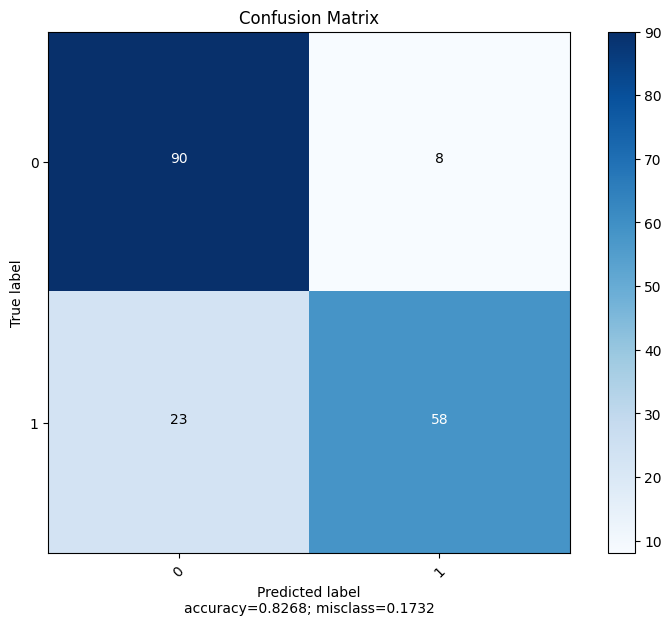

In [32]:
plot_confusion_matrix(cm           = array,
                      normalize    = False,
                      target_names = ['0', '1'],
                      title        = "Confusion Matrix")

## Kaggle submit

In [33]:
test_df = pd.read_csv('dataset/titanic/test.csv', index_col=0)
test_df.info()
test_df.sample(10)

<class 'pandas.core.frame.DataFrame'>
Index: 418 entries, 892 to 1309
Data columns (total 10 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Pclass    418 non-null    int64  
 1   Name      418 non-null    object 
 2   Sex       418 non-null    object 
 3   Age       332 non-null    float64
 4   SibSp     418 non-null    int64  
 5   Parch     418 non-null    int64  
 6   Ticket    418 non-null    object 
 7   Fare      417 non-null    float64
 8   Cabin     91 non-null     object 
 9   Embarked  418 non-null    object 
dtypes: float64(2), int64(3), object(5)
memory usage: 35.9+ KB


,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
PassengerId,,,,,,,,,,
1240,2,"Giles, Mr. Ralph",male,24.0,0,0,248726,13.5000,NaN,S
1180,3,"Mardirosian, Mr. Sarkis",male,NaN,0,0,2655,7.2292,F E46,C
899,2,"Caldwell, Mr. Albert Francis",male,26.0,1,1,248738,29.0000,NaN,S
1028,3,"Zakarian, Mr. Mapriededer",male,26.5,0,0,2656,7.2250,NaN,C
944,2,"Hocking, Miss. Ellen Nellie""""",female,20.0,2,1,29105,23.0000,NaN,S
1157,3,"Lyntakoff, Mr. Stanko",male,NaN,0,0,349235,7.8958,NaN,S
923,2,"Jefferys, Mr. Clifford Thomas",male,24.0,2,0,C.A. 31029,31.5000,NaN,S
1176,3,"Rosblom, Miss. Salli Helena",female,2.0,1,1,370129,20.2125,NaN,S
895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S


In [34]:
test_X = process_new_input_df(test_df, dropped_cols, mean_mode_dict, X_mean, X_std)
test_X = cattorch.Tensor(test_X)

418
<class 'pandas.core.frame.DataFrame'>
Index: 418 entries, 892 to 1309
Data columns (total 24 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Pclass         418 non-null    int64  
 1   Age            418 non-null    float64
 2   SibSp          418 non-null    int64  
 3   Parch          418 non-null    int64  
 4   female         418 non-null    float64
 5    Mr            418 non-null    float64
 6    Jonkheer      418 non-null    float64
 7    Lady          418 non-null    float64
 8    Mme           418 non-null    float64
 9    Miss          418 non-null    float64
 10   Dr            418 non-null    float64
 11   Mrs           418 non-null    float64
 12   Rev           418 non-null    float64
 13   Capt          418 non-null    float64
 14   the Countess  418 non-null    float64
 15   Mlle          418 non-null    float64
 16   Don           418 non-null    float64
 17   Ms            418 non-null    float64
 18   Major  

In [35]:
model = model.eval()
logits = model(test_X)
pred = logits.argmax(dim=-1)

In [36]:
submit_df = pd.DataFrame({"PassengerId": test_df.index, "Survived": pred.asnumpy()})
submit_df.to_csv("dataset/titanic/gender_submission.csv", index=False)